# Estructuras incompatibles y control predictivo negativo

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** Niveles 1–2; validación y regularización; 55 min.

## Objetivos

Examine información complementaria, mida el efecto de un prior estructural y diagnostique pérdida predictiva si el prior entra en conflicto. Distinga error del modelo, ajuste de datos y valor del objetivo.

## Preparación

Ejecute en el entorno de notebooks del repositorio. Versiones exactas: `pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8`. No se descargan ni modifican entradas.

## Datos

Desplace la interfaz verdadera de una propiedad conservando el prior de estructura común. Compare ajustes independientes y conjuntos con observaciones reservadas que nunca recibe el objetivo. Prueba un mecanismo de fallo, no un rechazo universal de inversión conjunta. El contexto del producto es la evidencia sintética M11 guardada `JOINT_SHARED` y `JOINT_CONFLICT`; los ejercicios generan arreglos reproducibles en memoria.

## Método

Para modalidad m, la discrepancia blanqueada es `0.5 ||W_m(G_m m_m − d_m)||²`. El acoplamiento penaliza `|∇ρ × ∇χ|²` con escala: favorece gradientes paralelos, sin exigir amplitudes iguales. Malla, escala, cobertura, ruido y λ influyen en el prior.

Conexión de producción: `data-pipeline/joint_survey_objective.py` evalúa términos gravimétricos y magnéticos separados; `joint_survey_structure.py` usa SimPEG CrossGradient y calcula objetivo físico, gradiente y productos Hessiano-vector; `joint_survey_optimizer.py` ajusta baselines estacionarios separados y exige validación de desarrollo antes de seleccionar acoplamiento. Estos experimentos de núcleos genéricos no llaman a esos solvers de prismas ni afirman reproducir M11. `data-pipeline/joint.py` genera otros artefactos sintéticos.


### Laboratorio A — sensibilidad y espacio nulo

Inspeccione valores singulares y rango por modalidad y en el sistema apilado. ¿Por qué mayor rango no prueba unicidad?

Entorno: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}
JOINT_SHARED density RMSE coupled/independent 1.0042 susceptibility RMSE ratio 0.9977 gravity/magnetic WRMS 1.089 1.005
JOINT_CONFLICT density RMSE coupled/independent 1.0001 susceptibility RMSE ratio 0.9993 gravity/magnetic WRMS 1.042 1.057
singular values: [1.6306 0.9006] [1.459  0.8008] [1.6479 1.4403 1.2041]
ranks: 2 2 3
model RMSE: 0.6401 0.3596 0.0028


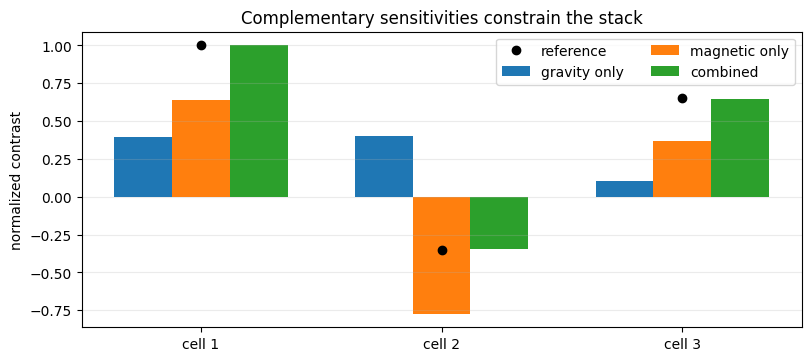

In [1]:
from importlib.metadata import version
import json,pathlib,numpy as np,matplotlib.pyplot as plt
# Registrar versiones fijadas del entorno de cálculo.
print("Entorno:",{name:version(name) for name in ("numpy","scipy","matplotlib")})
root=next(p for p in (pathlib.Path.cwd(),*pathlib.Path.cwd().parents) if (p/"data-pipeline/joint_survey_structure.py").is_file())
records={n:json.loads((root/f"data/derived/v2/{n}/regularization.json").read_text()) for n in ("JOINT_SHARED","JOINT_CONFLICT")}
for n,r in records.items():
 m=r["methods"];a=m["joint-uncoupled"]["metrics"];j=m["joint"]["metrics"]
 print(n,"density RMSE coupled/independent",round(j["model_rmse"]/a["model_rmse"],4),"susceptibility RMSE ratio",round(j["magnetic_model_rmse"]/a["magnetic_model_rmse"],4),"gravity/magnetic WRMS",round(j["wrms"],3),round(j["magnetic_wrms"],3))
# Algebraic sensitivity control (dimensionless; explicitly not physical prism responses).
Gg=np.array([[1.,.9,.1],[.1,.8,1.]]);Gm=np.array([[.9,-.8,.1],[.1,-.7,.9]]);truth=np.array([1.,-.35,.65]);eps=np.array([.015,-.01,-.012,.008]);dg=Gg@truth+eps[:2];dm=Gm@truth+eps[2:]
ops=[Gg,Gm,np.vstack([Gg,Gm])];obs=[dg,dm,np.r_[dg,dm]];fits=[np.linalg.lstsq(g,d,rcond=None)[0] for g,d in zip(ops,obs)]
print("singular values:",*[np.round(np.linalg.svd(g,compute_uv=False),4) for g in ops]);print("ranks:",*[np.linalg.matrix_rank(g) for g in ops]);print("model RMSE:",*[round(float(np.sqrt(np.mean((v-truth)**2))),4) for v in fits])
fig,ax=plt.subplots(figsize=(8,3.5),constrained_layout=True);x=np.arange(3)
for off,v,label in zip([-.24,0,.24],fits,["gravity only","magnetic only","combined"]):ax.bar(x+off,v,.24,label=label)
ax.plot(x,truth,"ko",label="reference");ax.set(xticks=x,xticklabels=["cell 1","cell 2","cell 3"],ylabel="normalized contrast",title="Complementary sensitivities constrain the stack");ax.legend(ncol=2);ax.grid(axis="y",alpha=.25);plt.show();assert np.linalg.matrix_rank(np.vstack(ops))==3


### Laboratorio B — barrido controlado de acoplamiento

Solo cambia λ. La partición entrenamiento/reserva se fija antes del ajuste; el objetivo solo recibe entrenamiento.

training-only independent cross-gradient scale 0.0003016212014748414 baseline converged True
lambda 0.0 converged True heldout WRMS gravity/magnetic [0.931 0.903] model RMSE density/susceptibility [0.007 0.008] cross-gradient norm 0.0174
lambda 0.03 converged True heldout WRMS gravity/magnetic [0.93  0.902] model RMSE density/susceptibility [0.008 0.007] cross-gradient norm 0.0095
lambda 0.3 converged True heldout WRMS gravity/magnetic [0.929 0.902] model RMSE density/susceptibility [0.009 0.006] cross-gradient norm 0.0022
lambda 3.0 converged True heldout WRMS gravity/magnetic [0.929 0.903] model RMSE density/susceptibility [0.009 0.006] cross-gradient norm 0.0012
lambda 30.0 converged True heldout WRMS gravity/magnetic [0.932 0.906] model RMSE density/susceptibility [0.009 0.006] cross-gradient norm 0.0009


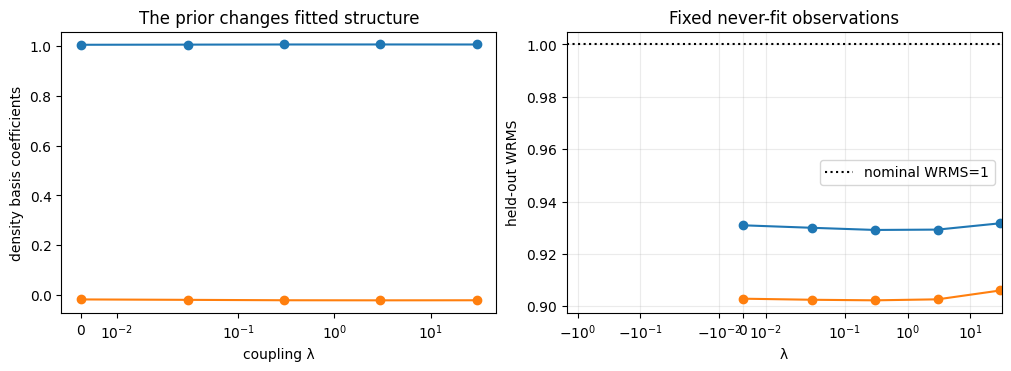

In [2]:
import numpy as np,matplotlib.pyplot as plt
from scipy.optimize import minimize
# Small dimensionless 2-D experiment with generic kernels, not prism physics/M11.
nz,nx=9,15;z=np.linspace(.15,1.,nz);x=np.linspace(-1.,1.,nx);X,Z=np.meshgrid(x,z);grid=np.c_[X.ravel(),Z.ravel()]
interface=.28+.12*np.sin(np.pi*X);base=np.tanh((Z-interface)/.12);shift=np.tanh((Z-interface-.20)/.12);back=Z-.5;Bg=np.stack([base,shift,back]);Bm=Bg.copy()
def kernels(seed):
 r=np.random.default_rng(seed);rx=r.uniform(-1.25,1.25,96);h=r.uniform(.03,.18,96);dx=rx[:,None]-grid[None,:,0];zz=grid[None,:,1]+h[:,None];return 1/(dx*dx+zz*zz)**1.5
Gg=kernels(2417);Gm=kernels(2418)*(.35+np.abs(grid[None,:,0]));Gg/=np.linalg.norm(Gg,axis=1,keepdims=True);Gm/=np.linalg.norm(Gm,axis=1,keepdims=True)
rng=np.random.default_rng(2419);order=rng.permutation(96);train,held=order[:72],order[72:];truth_g=(Bg[0]).ravel();truth_m=.7*(Bm[0]).ravel();sg=sm=.025
yg=Gg@truth_g+rng.normal(0,sg,96);ym=Gm@truth_m+rng.normal(0,sm,96)
def cross(a,b):
 az,ax=np.gradient(a,z,x);bz,bx=np.gradient(b,z,x);return float(np.mean((ax*bz-az*bx)**2))
q0=np.array([.2,.2,0.,.2,.2,0.]);scale=max(cross(np.tensordot(q0[:3],Bg,axes=(0,0)).reshape(nz,nx),np.tensordot(q0[3:],Bm,axes=(0,0)).reshape(nz,nx)),1e-12)
def objective(q,lam):
 a=np.tensordot(q[:3],Bg,axes=(0,0)).ravel();b=np.tensordot(q[3:],Bm,axes=(0,0)).ravel();rg=(Gg[train]@a-yg[train])/sg;rm=(Gm[train]@b-ym[train])/sm
 return .5*(rg@rg+rm@rm)+.08*(q@q)+lam*cross(a.reshape(nz,nx),b.reshape(nz,nx))/scale
# Calibrate the cross-gradient scale from a separate uncoupled fit on training rows only.
independent=minimize(objective,q0,args=(0.,),method="L-BFGS-B",bounds=[(-2,2)]*6,options={"maxiter":350,"ftol":1e-11})
qi=independent.x;ai=np.tensordot(qi[:3],Bg,axes=(0,0)).reshape(nz,nx);bi=np.tensordot(qi[3:],Bm,axes=(0,0)).reshape(nz,nx);scale=max(cross(ai,bi),1e-12)
print("training-only independent cross-gradient scale",scale,"baseline converged",independent.success)
lambdas=[0.,.03,.3,3.,30.];fits=[];held_metrics=[]
for lam in lambdas:
 fit=minimize(objective,q0,args=(lam,),method="L-BFGS-B",bounds=[(-2,2)]*6,options={"maxiter":350,"ftol":1e-11});q=fit.x;fits.append(q);a=np.tensordot(q[:3],Bg,axes=(0,0)).ravel();b=np.tensordot(q[3:],Bm,axes=(0,0)).ravel()
 hwr=(np.sqrt(np.mean(((Gg[held]@a-yg[held])/sg)**2)),np.sqrt(np.mean(((Gm[held]@b-ym[held])/sm)**2)));mr=(np.sqrt(np.mean((a-truth_g)**2)),np.sqrt(np.mean((b-truth_m)**2)));held_metrics.append(hwr)
 print("lambda",lam,"converged",fit.success,"heldout WRMS gravity/magnetic",np.round(hwr,3),"model RMSE density/susceptibility",np.round(mr,3),"cross-gradient norm",round(np.sqrt(cross(a.reshape(nz,nx),b.reshape(nz,nx))),4));assert fit.success
fig,ax=plt.subplots(1,2,figsize=(10,3.6),constrained_layout=True);ax[0].plot(lambdas,np.array(fits)[:,:2],"o-");ax[0].set_xscale("symlog",linthresh=.03);ax[0].set(xlabel="coupling λ",ylabel="density basis coefficients",title="The prior changes fitted structure")
ax[1].plot(lambdas,np.array(held_metrics),"o-");ax[1].axhline(1,color="k",ls=":",label="nominal WRMS=1");ax[1].set_xscale("symlog",linthresh=.03);ax[1].set(xlabel="λ",ylabel="held-out WRMS",title="Fixed never-fit observations");ax[1].legend();ax[1].grid(alpha=.25);plt.show()


### Laboratorio C — control negativo de prior incompatible

Los límites verdaderos difieren. Compare predicción reservada y RMSE con λ=0; reducir gradiente cruzado no basta.

conflict training-only independent cross-gradient scale 3.0555103097770617 baseline converged True
lambda 0.0 converged True train WRMS [0.963 5.778] heldout WRMS [0.983 4.918] model RMSE [0.011 0.604]
 optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
lambda 0.03 converged True train WRMS [0.963 5.778] heldout WRMS [0.983 4.918] model RMSE [0.011 0.604]
 optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
lambda 0.3 converged True train WRMS [0.963 5.778] heldout WRMS [0.983 4.917] model RMSE [0.011 0.604]
 optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
lambda 3.0 converged True train WRMS [0.963 5.778] heldout WRMS [0.983 4.914] model RMSE [0.011 0.604]
 optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
lambda 30.0 converged True train WRMS [0.963 5.78 ] heldout WRMS [0.985 4.888] model RMSE [0.009 0.602]
 optimizer message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
strong/independent 

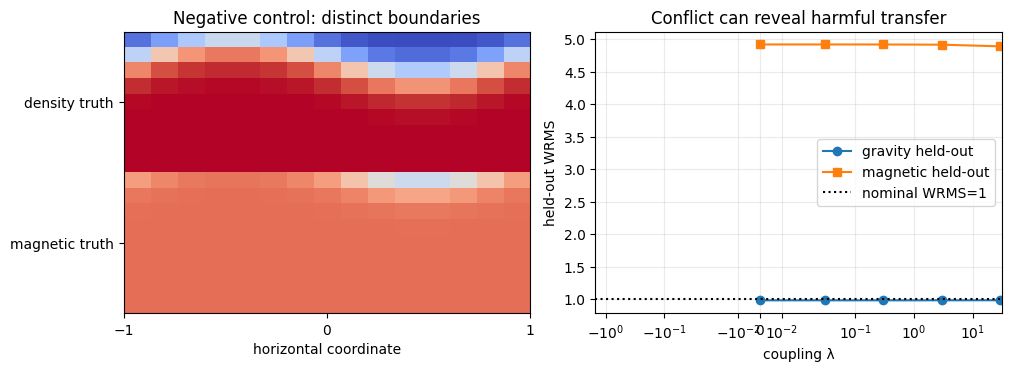

In [3]:
import numpy as np,matplotlib.pyplot as plt
from scipy.optimize import minimize
# Negative control: the true interfaces differ; held-out rows remain excluded.
truth_g=np.tanh((Z-interface)/.12).ravel();truth_m=.7*np.tanh((Z-(interface-.23))/.12).ravel();r=np.random.default_rng(991);ygc=Gg@truth_g+r.normal(0,sg,96);ymc=Gm@truth_m+r.normal(0,sm,96)
q0c=np.array([.3,.1,0.,.3,.1,0.]);scale_c=max(cross(np.tensordot(q0c[:3],Bg,axes=(0,0)).reshape(nz,nx),np.tensordot(q0c[3:],Bm,axes=(0,0)).reshape(nz,nx)),1e-12)
def objective_conflict(q,lam):
 a=np.tensordot(q[:3],Bg,axes=(0,0)).ravel();b=np.tensordot(q[3:],Bm,axes=(0,0)).ravel();rg=(Gg[train]@a-ygc[train])/sg;rm=(Gm[train]@b-ymc[train])/sm
 return .5*(rg@rg+rm@rm)+.08*(q@q)+lam*cross(a.reshape(nz,nx),b.reshape(nz,nx))/scale_c
# Use a training-only independent fit to set the structural-term scale.
independent_c=minimize(objective_conflict,q0c,args=(0.,),method="L-BFGS-B",bounds=[(-2,2)]*6,options={"maxiter":350,"ftol":1e-11})
qic=independent_c.x;aic=np.tensordot(qic[:3],Bg,axes=(0,0)).reshape(nz,nx);bic=np.tensordot(qic[3:],Bm,axes=(0,0)).reshape(nz,nx);scale_c=max(cross(aic,bic),1e-12)
print("conflict training-only independent cross-gradient scale",scale_c,"baseline converged",independent_c.success)
lams=[0.,.03,.3,3.,30.];rows=[];start=q0c.copy()
for lam in lams:
 f=minimize(objective_conflict,start,args=(lam,),method="L-BFGS-B",bounds=[(-2,2)]*6,options={"maxiter":1200,"ftol":1e-11});q=f.x;start=q.copy();a=np.tensordot(q[:3],Bg,axes=(0,0)).ravel();b=np.tensordot(q[3:],Bm,axes=(0,0)).ravel();tr=(np.sqrt(np.mean(((Gg[train]@a-ygc[train])/sg)**2)),np.sqrt(np.mean(((Gm[train]@b-ymc[train])/sm)**2)));ho=(np.sqrt(np.mean(((Gg[held]@a-ygc[held])/sg)**2)),np.sqrt(np.mean(((Gm[held]@b-ymc[held])/sm)**2)));mr=(np.sqrt(np.mean((a-truth_g)**2)),np.sqrt(np.mean((b-truth_m)**2)));rows.append((tr,ho,mr));print("lambda",lam,"converged",f.success,"train WRMS",np.round(tr,3),"heldout WRMS",np.round(ho,3),"model RMSE",np.round(mr,3));print(" optimizer message:",f.message)
print("strong/independent ratios (heldout gravity, magnetic; model density, susceptibility):",np.round(np.array([*rows[-1][1],*rows[-1][2]])/np.array([*rows[0][1],*rows[0][2]]),3))
fig,ax=plt.subplots(1,2,figsize=(10,3.6),constrained_layout=True);ax[0].imshow(np.vstack([truth_g.reshape(nz,nx),truth_m.reshape(nz,nx)]),aspect="auto",extent=[x.min(),x.max(),2,0],cmap="coolwarm");ax[0].set(xticks=[-1,0,1],yticks=[.5,1.5],yticklabels=["density truth","magnetic truth"],xlabel="horizontal coordinate",title="Negative control: distinct boundaries")
ho=np.array([r[1] for r in rows]);ax[1].plot(lams,ho[:,0],"o-",label="gravity held-out");ax[1].plot(lams,ho[:,1],"s-",label="magnetic held-out");ax[1].axhline(1,color="k",ls=":",label="nominal WRMS=1");ax[1].set_xscale("symlog",linthresh=.03);ax[1].set(xlabel="coupling λ",ylabel="held-out WRMS",title="Conflict can reveal harmful transfer");ax[1].legend();ax[1].grid(alpha=.25);plt.show()


## Estado del arte

El gradiente cruzado es una regularización estructural de inversión conjunta de campos potenciales. La sensibilidad complementaria ayuda si son plausibles límites compartidos; estructuras disjuntas pueden transferir error. M11 usa escalas físicas y selección validada; este experimento no reproduce su optimizador.

## Resultados

Use rango y valores singulares (A), error del modelo por propiedad y WRMS reservado (B), y el barrido incompatible (C). Indique partición, unidades y alcance sintético.

## Resumen

El objetivo conjunto puede mejorar condicionamiento o imponer una relación geológica falsa. Fundamente λ con predicciones reservadas de ambas modalidades y recuperación. Estos experimentos no prueban elegibilidad de campo, parámetros universales ni desempeño de producción M11.

## Referencias

- [Tutorial SimPEG de gradiente cruzado para campos potenciales](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- [Guía de inversión pyGIMLi](https://www.pygimli.org/user-guide/inversion/)